# 09 — Regularização: Ridge e Lasso

Desde o notebook 02, a regressão linear tem um problema que adiamos: a **multicolinearidade**. Colunas parecidas, como `AveRooms` e `AveBedrms`, "brigam" entre si e geram coeficientes estranhos, com sinais opostos e difíceis de interpretar.

Neste notebook extra, voltamos à regressão linear para entender a **regularização**, uma das ideias mais importantes de Machine Learning. Ela aparece em quase todo modelo moderno. Você vai aprender:

- Por que os coeficientes da regressão linear podem ser **instáveis**
- O que é **regularização**: penalizar coeficientes grandes
- **Ridge** (penalidade L2): encolhe todos os coeficientes
- **Lasso** (penalidade L1): zera coeficientes e **seleciona colunas**
- **Recursos polinomiais**: como um modelo linear pode aprender curvas
- Quando a regularização **faz diferença**, e quando não faz

> ⏱️ O notebook leva cerca de 2 minutos para rodar.

## 1. Importando bibliotecas e preparando os dados

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, KFold, cross_validate, validation_curve
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Ferramentas novas deste notebook:
from sklearn.linear_model import Ridge, Lasso                 # regressão linear com regularização
from sklearn.preprocessing import PolynomialFeatures          # cria colunas de produtos e potências

from atributos import criar_derivados, criar_dist_cidade

pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 100

df = fetch_california_housing(as_frame=True).frame
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

# A mesma divisão e as mesmas dobras de sempre.
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

## 2. O problema: coeficientes instáveis

No notebook 03 vimos que `AveRooms` (cômodos) e `AveBedrms` (quartos) recebiam coeficientes de **sinais opostos**. Vamos medir quão **confiáveis** são esses coeficientes.

O experimento: treinar a regressão linear **50 vezes**, cada vez com uma **amostra sorteada** de 10% do treino, e ver o quanto cada coeficiente muda. Se o modelo aprendesse algo sólido, os coeficientes deveriam ser parecidos em todas as amostras.

(Esse sorteio com reposição é o mesmo *bootstrap* da random forest, no notebook 04.)

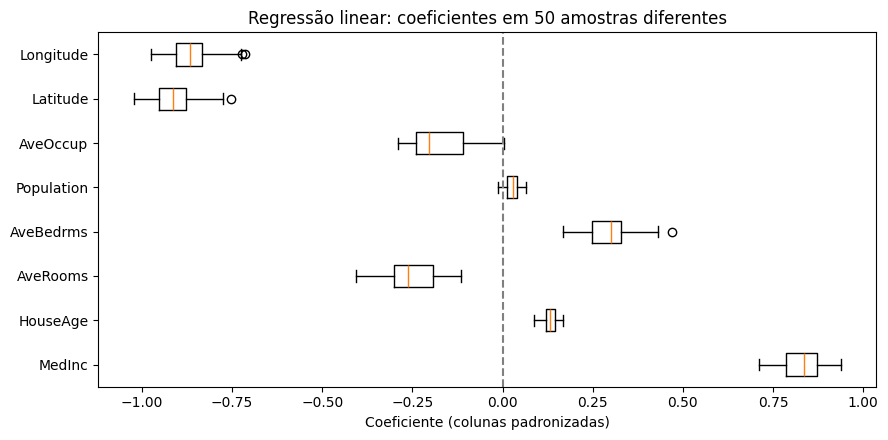

,mean,std
MedInc,0.832,0.054
HouseAge,0.131,0.020
AveRooms,-0.254,0.068
AveBedrms,0.294,0.072
Population,0.024,0.021
AveOccup,-0.172,0.091
Latitude,-0.909,0.059
Longitude,-0.861,0.060


In [2]:
def coeficientes_bootstrap(modelo, n_amostras=50, fracao=0.1, semente=42):
    """Treina o modelo em várias amostras sorteadas e devolve os coeficientes de cada uma."""
    gerador = np.random.default_rng(semente)       # gerador de números aleatórios reproduzível
    tamanho = int(len(X_train_full) * fracao)
    resultados = []
    for _ in range(n_amostras):                    # "_" é o nome convencional de uma variável que não usamos
        posicoes = gerador.choice(len(X_train_full), size=tamanho, replace=True)   # sorteio com reposição
        pipeline = Pipeline([("padronizar", StandardScaler()), ("modelo", modelo)])
        pipeline.fit(X_train_full.iloc[posicoes], y_train_full.iloc[posicoes])
        resultados.append(pipeline["modelo"].coef_)
    return pd.DataFrame(resultados, columns=X_train_full.columns)


coefs_linear = coeficientes_bootstrap(LinearRegression())

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot(coefs_linear.values, vert=False)
ax.set_yticks(range(1, len(coefs_linear.columns) + 1), coefs_linear.columns)
ax.axvline(0, color="gray", linestyle="--")
ax.set_xlabel("Coeficiente (colunas padronizadas)")
ax.set_title("Regressão linear: coeficientes em 50 amostras diferentes")
plt.tight_layout()
plt.show()

coefs_linear.agg(["mean", "std"]).T.round(3)

In [3]:
# Por que justamente esses coeficientes oscilam? Veja as correlações entre colunas:
print(f"Correlação AveRooms × AveBedrms:  {X_train_full['AveRooms'].corr(X_train_full['AveBedrms']):+.2f}")
print(f"Correlação Latitude × Longitude:  {X_train_full['Latitude'].corr(X_train_full['Longitude']):+.2f}")

Correlação AveRooms × AveBedrms:  +0.84
Correlação Latitude × Longitude:  -0.92


**Conclusão:** os coeficientes que mais oscilam (maiores caixas e desvios) são justamente os de **colunas muito correlacionadas**:
- `AveRooms` e `AveBedrms` têm correlação de **+0,84**. O coeficiente de `AveBedrms` varia com desvio de 0,07 em torno de 0,29.
- `Latitude` e `Longitude` têm correlação de **−0,92** (a Califórnia é uma faixa diagonal no mapa: quanto mais ao norte, mais a oeste). Seus coeficientes são enormes (≈ −0,9 cada) e se compensam.

🎓 **Por que isso acontece?** Se duas colunas carregam quase a mesma informação, o modelo pode "dividir o crédito" entre elas de infinitas formas. Por exemplo, +0,3 numa e −0,2 na outra prevê quase o mesmo que +0,1 e 0,0. Pequenas mudanças nos dados mudam qual divisão ele escolhe. As **previsões** continuam boas, mas os **coeficientes** deixam de ser confiáveis para interpretação.

É como duas pessoas carregando juntas uma mesa: dá para saber o peso total, mas não quanto cada uma está segurando.

## 🎓 Conceito: regularização

A regressão linear comum escolhe os coeficientes que minimizam **só o erro**:

$$\text{custo} = \text{erro}$$

A **regularização** acrescenta uma **penalidade** para coeficientes grandes:

$$\text{custo} = \text{erro} + \alpha \times \text{tamanho dos coeficientes}$$

Agora o modelo precisa equilibrar duas coisas: **errar pouco** e **manter os coeficientes pequenos**. Um coeficiente só fica grande se "pagar" por isso, reduzindo bastante o erro.

O **α** (alfa) é um **hiperparâmetro** que controla o peso da penalidade:
- **α = 0:** sem penalidade. É a regressão linear comum.
- **α pequeno:** penalidade leve.
- **α grande:** os coeficientes são "espremidos" em direção a zero. No extremo, o modelo prevê só a média.

Há duas formas principais de medir o "tamanho dos coeficientes":

| Modelo | Penalidade | Efeito |
|---|---|---|
| **Ridge** | Soma dos **quadrados** dos coeficientes (L2) | Encolhe todos os coeficientes, mas nenhum chega a zero |
| **Lasso** | Soma dos **valores absolutos** (L1) | Encolhe e **zera** alguns coeficientes: faz seleção de colunas |

⚠️ **A padronização é obrigatória.** A penalidade compara o tamanho dos coeficientes entre si. Sem padronizar, uma coluna em escala grande (como `Population`) teria coeficientes naturalmente minúsculos e quase não seria penalizada (notebook 03). Por isso, todo modelo regularizado deste notebook vem depois de um `StandardScaler`.

**Conexão com outros notebooks:** você já viu regularização sem esse nome. O `l2_regularization` do gradient boosting (notebook 08) e o `min_samples_leaf` das árvores também "freiam" o modelo para evitar que ele se ajuste demais aos dados.

## 3. Ridge estabiliza os coeficientes

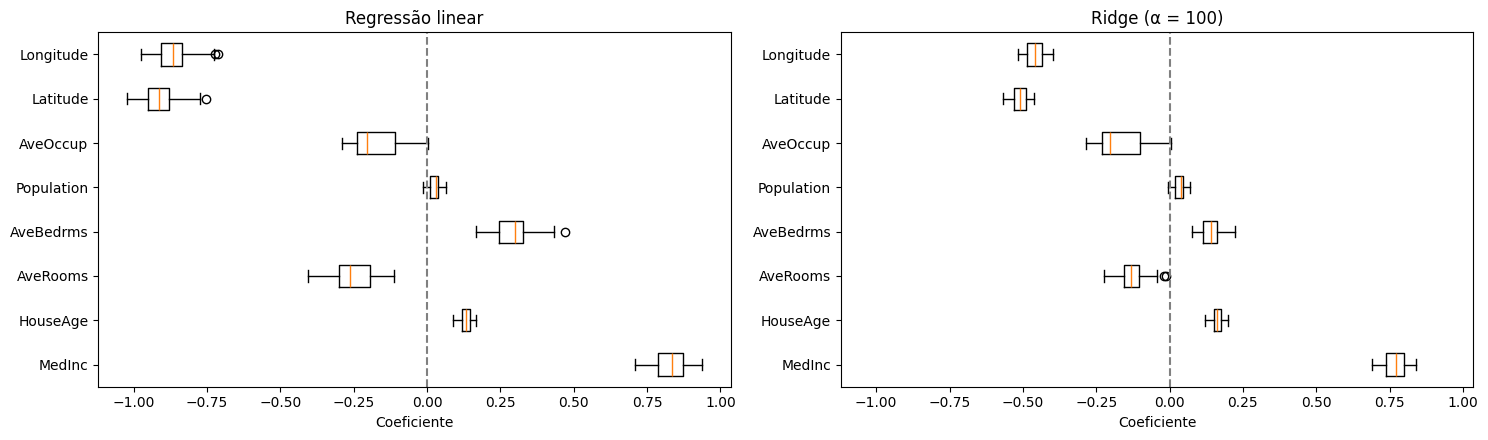

,desvio (linear),desvio (Ridge),média (linear),média (Ridge)
MedInc,0.054,0.037,0.832,0.770
HouseAge,0.020,0.019,0.131,0.162
AveRooms,0.068,0.048,-0.254,-0.127
AveBedrms,0.072,0.035,0.294,0.142
Population,0.021,0.019,0.024,0.032
AveOccup,0.091,0.087,-0.172,-0.170
Latitude,0.059,0.028,-0.909,-0.512
Longitude,0.060,0.031,-0.861,-0.458


In [4]:
coefs_ridge = coeficientes_bootstrap(Ridge(alpha=100))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharex=True)
for ax, coefs, titulo in [(axes[0], coefs_linear, "Regressão linear"), (axes[1], coefs_ridge, "Ridge (α = 100)")]:
    ax.boxplot(coefs.values, vert=False)
    ax.set_yticks(range(1, len(coefs.columns) + 1), coefs.columns)
    ax.axvline(0, color="gray", linestyle="--")
    ax.set_title(titulo)
    ax.set_xlabel("Coeficiente")
plt.tight_layout()
plt.show()

pd.DataFrame({
    "desvio (linear)": coefs_linear.std(),
    "desvio (Ridge)": coefs_ridge.std(),
    "média (linear)": coefs_linear.mean(),
    "média (Ridge)": coefs_ridge.mean(),
}).round(3)

**Conclusão:** com Ridge, as caixas ficam **mais estreitas**. Os coeficientes variam bem menos de uma amostra para outra:
- O desvio de `AveBedrms` caiu pela metade (0,072 → 0,035), e o de `Latitude`/`Longitude` também (~0,06 → ~0,03).
- Os coeficientes das colunas correlacionadas foram **encolhidos**: `Latitude` foi de −0,91 para −0,51, e `AveBedrms` de 0,29 para 0,14. A penalidade impede que elas fiquem "brigando" com valores enormes de sinais opostos.
- `MedInc`, que não tem uma "gêmea", quase não mudou (0,83 → 0,77).

O Ridge troca um pouco de **viés** (os coeficientes ficam um pouco menores que o "ideal" nos dados de treino) por muito menos **variância** (eles ficam estáveis). Essa troca entre viés e variância é um dos conceitos centrais de Machine Learning.

## 4. O caminho dos coeficientes no Ridge

O que acontece com cada coeficiente conforme aumentamos o α? Vamos usar o pipeline completo do notebook 03 (atributos derivados + log + distância + padronização), com 11 colunas.

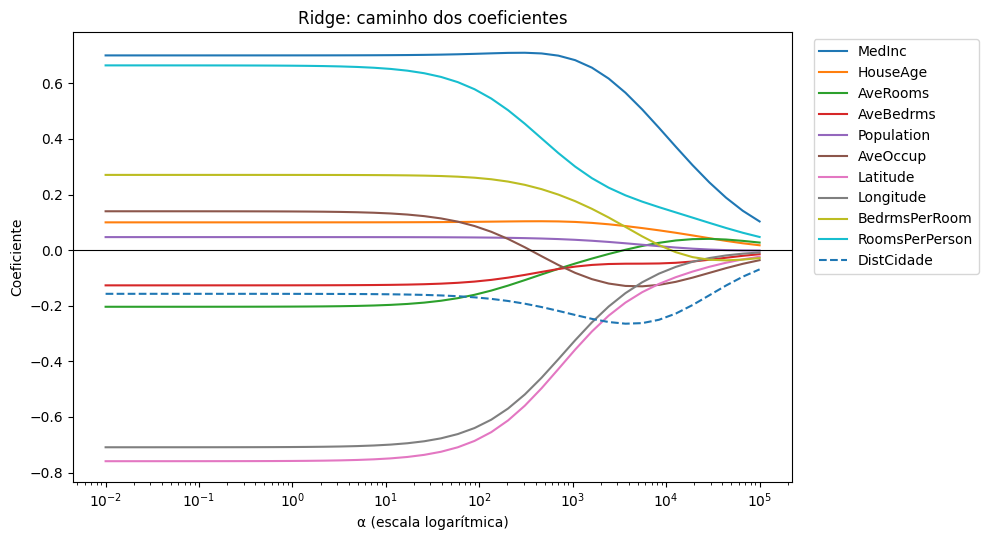

In [5]:
def aplicar_log(X):
    """log(1 + x) nas colunas com cauda longa (como no notebook 03)."""
    X = X.copy()
    for coluna in ["AveRooms", "AveBedrms", "Population", "AveOccup", "RoomsPerPerson"]:
        if coluna in X.columns:
            X[coluna] = np.log1p(X[coluna])
    return X


def preparo_nb03():
    """As etapas de preparo do notebook 03, numa lista pronta para virar pipeline."""
    return [
        ("derivados", FunctionTransformer(criar_derivados)),
        ("log", FunctionTransformer(aplicar_log)),
        ("dist_cidade", FunctionTransformer(criar_dist_cidade)),
        ("padronizar", StandardScaler()),
    ]


# Prepara os dados uma vez, para o gráfico (sem pipeline: aqui só queremos ver os coeficientes).
preparo = Pipeline(preparo_nb03()).set_output(transform="pandas")   # set_output mantém os nomes das colunas
X_preparado = preparo.fit_transform(X_train_full)

alfas = np.logspace(-2, 5, 40)   # 40 valores de 0,01 a 100.000, igualmente espaçados em escala log
caminho_ridge = pd.DataFrame(
    [Ridge(alpha=a).fit(X_preparado, y_train_full).coef_ for a in alfas],
    index=alfas, columns=X_preparado.columns,
)

fig, ax = plt.subplots(figsize=(10, 5.5))
# A paleta padrão tem só 10 cores; da 11ª coluna em diante, usamos linha tracejada para não confundir.
for i, coluna in enumerate(caminho_ridge.columns):
    ax.plot(caminho_ridge.index, caminho_ridge[coluna], label=coluna, linestyle="--" if i >= 10 else "-")
ax.set_xscale("log")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("α (escala logarítmica)")
ax.set_ylabel("Coeficiente")
ax.set_title("Ridge: caminho dos coeficientes")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")   # legenda fora do gráfico, à direita
plt.tight_layout()
plt.show()

**Conclusão:**
- **À esquerda (α pequeno):** os coeficientes são os da regressão linear comum, com alguns valores grandes e de sinais opostos.
- **Conforme o α aumenta**, todos os coeficientes são puxados em direção a zero. Os pares que "brigavam" convergem primeiro.
- **À direita (α enorme):** todos ficam praticamente em zero, e o modelo vira o baseline que prevê a média.
- **Nenhum coeficiente chega exatamente a zero** antes do fim: o Ridge **encolhe**, mas não elimina colunas.

## 5. O caminho dos coeficientes no Lasso

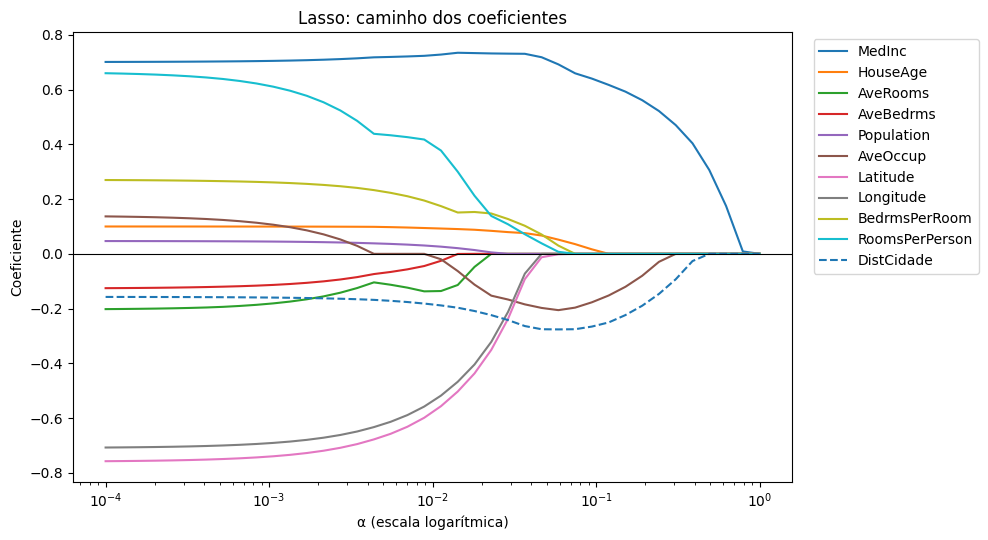

α = 0.001: 11 colunas -> ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'BedrmsPerRoom', 'RoomsPerPerson', 'DistCidade']
α = 0.01 : 11 colunas -> ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'BedrmsPerRoom', 'RoomsPerPerson', 'DistCidade']
α = 0.05 :  7 colunas -> ['MedInc', 'HouseAge', 'AveOccup', 'Latitude', 'BedrmsPerRoom', 'RoomsPerPerson', 'DistCidade']
α = 0.1  :  4 colunas -> ['MedInc', 'HouseAge', 'AveOccup', 'DistCidade']
α = 0.3  :  2 colunas -> ['MedInc', 'DistCidade']


In [6]:
alfas_lasso = np.logspace(-4, 0, 40)   # o Lasso zera coeficientes com α bem menores que o Ridge
caminho_lasso = pd.DataFrame(
    [Lasso(alpha=a, max_iter=10_000).fit(X_preparado, y_train_full).coef_ for a in alfas_lasso],
    index=alfas_lasso, columns=X_preparado.columns,
)

fig, ax = plt.subplots(figsize=(10, 5.5))
for i, coluna in enumerate(caminho_lasso.columns):
    ax.plot(caminho_lasso.index, caminho_lasso[coluna], label=coluna, linestyle="--" if i >= 10 else "-")
ax.set_xscale("log")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("α (escala logarítmica)")
ax.set_ylabel("Coeficiente")
ax.set_title("Lasso: caminho dos coeficientes")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Quantas colunas sobrevivem (coeficiente diferente de zero) para alguns valores de α?
for a in [0.001, 0.01, 0.05, 0.1, 0.3]:
    modelo = Lasso(alpha=a, max_iter=10_000).fit(X_preparado, y_train_full)
    sobreviventes = X_preparado.columns[modelo.coef_ != 0]
    print(f"α = {a:<5}: {len(sobreviventes):>2} colunas -> {list(sobreviventes)}")

**Conclusão:** diferente do Ridge, o Lasso leva coeficientes **exatamente a zero**, um de cada vez, conforme o α aumenta. Ele faz **seleção de colunas** automaticamente:
- **α = 0,05:** ficam 7 colunas. Saem `AveRooms`, `AveBedrms`, `Population` e `Longitude`.
- **α = 0,1:** ficam só 4 colunas: `MedInc`, `HouseAge`, `AveOccup` e `DistCidade`.
- **α = 0,3:** sobram apenas `MedInc` e `DistCidade`, a **renda** e a **localização**. São as duas informações que todos os notebooks apontaram como as mais importantes.

Repare como o Lasso lida com os **pares correlacionados**: de `Latitude`/`Longitude`, a `Longitude` sai primeiro. De `AveRooms`/`AveBedrms`, os dois saem, e ficam as proporções criadas no notebook 03 (`BedrmsPerRoom` e `RoomsPerPerson`), que carregam a mesma informação de forma mais útil. Em geral, o Lasso tende a **escolher uma coluna de cada grupo** de colunas parecidas.

No gráfico, o coeficiente de `AveOccup` chega a **trocar de sinal** (de positivo para negativo) enquanto `RoomsPerPerson`, que carrega informação parecida, vai sendo encolhida. Colunas correlacionadas "repassam" o crédito entre si conforme as outras saem. É mais um lembrete de que coeficientes individuais devem ser lidos com cuidado.

## 6. A regularização melhora o erro?

Vamos comparar, com validação cruzada, a regressão linear do notebook 03 com versões Ridge e Lasso.

In [7]:
placar = {}


def avaliar_cv(nome, modelo):
    """Validação cruzada com as 5 dobras de sempre; guarda e mostra o resultado."""
    inicio = time.time()
    cv = cross_validate(modelo, X_train_full, y_train_full, cv=kfold,
                        scoring="neg_mean_absolute_error", return_train_score=True)
    placar[nome] = {
        "MAE validação": -cv["test_score"].mean(),
        "± desvio": cv["test_score"].std(),
        "MAE treino": -cv["train_score"].mean(),
        "pior dobra": -cv["test_score"].min(),
    }
    r = placar[nome]
    print(f"{nome:<34} MAE {r['MAE validação']:.4f} ± {r['± desvio']:.4f}   "
          f"(treino {r['MAE treino']:.3f}, pior dobra {r['pior dobra']:.3f}, {time.time() - inicio:.1f} s)")


avaliar_cv("Linear (nb 03, 11 colunas)", Pipeline(preparo_nb03() + [("modelo", LinearRegression())]))
avaliar_cv("Ridge α=10 (11 colunas)", Pipeline(preparo_nb03() + [("modelo", Ridge(alpha=10))]))
avaliar_cv("Lasso α=0,01 (11 colunas)", Pipeline(preparo_nb03() + [("modelo", Lasso(alpha=0.01))]))

Linear (nb 03, 11 colunas)         MAE 0.4700 ± 0.0096   (treino 0.469, pior dobra 0.482, 0.1 s)


Ridge α=10 (11 colunas)            MAE 0.4700 ± 0.0095   (treino 0.469, pior dobra 0.482, 0.1 s)


Lasso α=0,01 (11 colunas)          MAE 0.4736 ± 0.0098   (treino 0.473, pior dobra 0.484, 0.2 s)


**Conclusão:** **não**, aqui a regularização não melhora o erro. O Ridge empata com a regressão comum (0,470), e o Lasso fica um pouco pior (0,474), porque descarta parte da informação.

O motivo é que **não há overfitting para corrigir**. Repare que o MAE de treino (0,469) é praticamente igual ao de validação (0,470). Com 16 mil casas e só 11 colunas, a regressão linear já é simples demais para decorar os dados. O problema dela é o **underfitting** (notebook 02), e a regularização, que **simplifica** o modelo, não resolve isso.

Então quando a regularização faz diferença? Quando o modelo tem **muitas** colunas e começa a decorar os dados. Vamos criar essa situação.

## 🎓 Conceito: recursos polinomiais

Um modelo linear só soma colunas multiplicadas por coeficientes, então ele desenha retas. Mas podemos **dar a ele colunas novas** que representam curvas e interações:

| Original | Grau 2 adiciona | Grau 3 adiciona também |
|---|---|---|
| `renda`, `idade` | `renda²`, `idade²`, `renda × idade` | `renda³`, `renda² × idade`, `renda × idade²`, `idade³` |

- `renda²` permite uma **curva** (lembra da aceleração da renda na dependência parcial do notebook 07?).
- `renda × idade` é uma **interação**: o efeito da renda pode depender da idade das casas.

O modelo continua "linear" (nos coeficientes), mas agora pode aprender relações curvas. Isso é engenharia de atributos **automática**.

O preço é que o número de colunas **explode**:

In [8]:
for grau in [1, 2, 3]:
    n_colunas = PolynomialFeatures(degree=grau, include_bias=False).fit(X_preparado).n_output_features_
    print(f"Grau {grau}: {n_colunas:>3} colunas")

Grau 1:  11 colunas
Grau 2:  77 colunas
Grau 3: 363 colunas


Com 11 colunas originais, o grau 3 gera **363 colunas**. Muitas são parecidas entre si, como `renda²` e `renda³`, ou seja, a multicolinearidade fica muito pior. É o ambiente perfeito para overfitting.

## 7. Recursos polinomiais sem regularização

In [9]:
def pipeline_polinomial(grau, modelo):
    """Preparo do nb 03 -> recursos polinomiais -> padroniza de novo -> modelo."""
    return Pipeline(preparo_nb03() + [
        ("polinomio", PolynomialFeatures(degree=grau, include_bias=False)),
        ("padronizar_de_novo", StandardScaler()),   # as colunas novas (ex.: renda³) têm escalas muito diferentes
        ("modelo", modelo),
    ])


avaliar_cv("Linear, polinômio grau 2", pipeline_polinomial(2, LinearRegression()))
avaliar_cv("Linear, polinômio grau 3", pipeline_polinomial(3, LinearRegression()))

Linear, polinômio grau 2           MAE 0.4085 ± 0.0106   (treino 0.403, pior dobra 0.424, 1.1 s)


Linear, polinômio grau 3           MAE 0.4620 ± 0.0775   (treino 0.358, pior dobra 0.563, 2.6 s)


**Conclusão:**
- **Grau 2 (77 colunas):** o erro cai de 0,470 para **0,409**. As curvas e interações ajudam muito a regressão linear, e o treino (0,403) continua perto da validação: pouco overfitting.
- **Grau 3 (363 colunas):** o erro **médio** piora (0,462), mas o mais grave é a **instabilidade**: o desvio salta para ± 0,078 e a pior dobra chega a **0,56**, pior que a regressão linear simples. Enquanto isso, o erro de treino é o menor de todos (0,358).

É o overfitting clássico. Com 363 colunas correlacionadas, o modelo encontra combinações de coeficientes enormes que se ajustam ao treino, mas que "explodem" em algumas casas novas, por exemplo nas com valores extremos de `AveOccup`.

## 8. Ridge resgata o modelo de grau 3

Tempo: 15 s


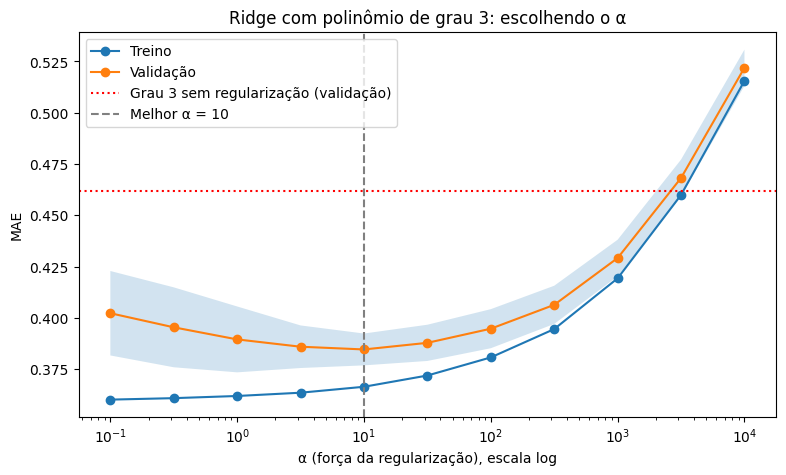

,MAE validação,± desvio,MAE treino
α,,,
0.10,0.402,0.021,0.360
0.32,0.395,0.019,0.361
1.00,0.389,0.016,0.362
3.16,0.386,0.010,0.363
10.00,0.385,0.008,0.366
31.62,0.388,0.009,0.372
100.00,0.395,0.009,0.381
316.23,0.406,0.009,0.395
1000.00,0.429,0.009,0.419


In [10]:
# validation_curve (notebook 05): validação cruzada para cada valor de α.
alfas_teste = np.logspace(-1, 4, 11)   # de 0,1 a 10.000

inicio = time.time()
scores_treino, scores_val = validation_curve(
    pipeline_polinomial(3, Ridge()),
    X_train_full, y_train_full,
    param_name="modelo__alpha", param_range=alfas_teste,
    cv=kfold, scoring="neg_mean_absolute_error",
)
print(f"Tempo: {time.time() - inicio:.0f} s")

mae_treino, mae_val, desvio_val = -scores_treino.mean(axis=1), -scores_val.mean(axis=1), scores_val.std(axis=1)
melhor_alfa = alfas_teste[np.argmin(mae_val)]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(alfas_teste, mae_treino, marker="o", label="Treino")
ax.plot(alfas_teste, mae_val, marker="o", label="Validação")
ax.fill_between(alfas_teste, mae_val - desvio_val, mae_val + desvio_val, alpha=0.2)
ax.axhline(placar["Linear, polinômio grau 3"]["MAE validação"], color="red", linestyle=":",
           label="Grau 3 sem regularização (validação)")
ax.axvline(melhor_alfa, color="gray", linestyle="--", label=f"Melhor α = {melhor_alfa:.3g}")
ax.set_xscale("log")
ax.set_xlabel("α (força da regularização), escala log")
ax.set_ylabel("MAE")
ax.set_title("Ridge com polinômio de grau 3: escolhendo o α")
ax.legend()
plt.show()

pd.DataFrame({"MAE validação": mae_val, "± desvio": desvio_val, "MAE treino": mae_treino},
             index=pd.Index(alfas_teste.round(2), name="α")).round(4)

**Conclusão:** o melhor valor é **α = 10**, com MAE de **0,385**, muito melhor que o grau 3 sem regularização (0,462, a linha vermelha pontilhada). O gráfico tem a forma de "U" que já vimos na curva de complexidade do notebook 04, só que espelhada:
- **α pequeno (à esquerda):** pouca regularização. A faixa de desvio é **larga** (± 0,02) porque o modelo ainda tem overfitting e varia muito entre as dobras.
- **α = 10:** o equilíbrio. O desvio cai para ± 0,008, e a distância entre treino e validação fica pequena.
- **α grande (à direita):** regularização demais. Treino e validação pioram juntos até ~0,52: o modelo foi tão "espremido" que entrou em **underfitting**.

Aqui o α funciona como o **inverso** do `max_depth` da árvore: aumentar o α **simplifica** o modelo, e aumentar o `max_depth` **complica**.

In [11]:
avaliar_cv(f"Ridge α={melhor_alfa:.3g}, polinômio grau 3", pipeline_polinomial(3, Ridge(alpha=melhor_alfa)))

Ridge α=10, polinômio grau 3       MAE 0.3845 ± 0.0078   (treino 0.366, pior dobra 0.395, 1.3 s)


## 9. Lasso no modelo de grau 3: quais colunas importam?

O Lasso também combate o overfitting, mas de outro jeito: **eliminando** colunas. Com 363 candidatas, ele mostra quais o modelo realmente usa.

In [12]:
inicio = time.time()
avaliar_cv("Lasso α=0,001, polinômio grau 3",
           pipeline_polinomial(3, Lasso(alpha=0.001, max_iter=5000)))

# Treina uma vez com todo o treino para inspecionar os coeficientes.
# set_output(transform="pandas") faz os nomes das colunas atravessarem o pipeline,
# então o PolynomialFeatures cria nomes legíveis como "MedInc Latitude" (= MedInc × Latitude).
lasso_grau3 = pipeline_polinomial(3, Lasso(alpha=0.001, max_iter=5000)).set_output(transform="pandas")
lasso_grau3.fit(X_train_full, y_train_full)

coefs = pd.Series(lasso_grau3["modelo"].coef_, index=lasso_grau3["modelo"].feature_names_in_)
print(f"\nColunas mantidas pelo Lasso: {(coefs != 0).sum()} de {len(coefs)}")
print(f"Tempo total: {time.time() - inicio:.0f} s")

# As 10 colunas com maior coeficiente (em valor absoluto).
coefs[coefs.abs().sort_values(ascending=False).index[:10]].round(3)

Lasso α=0,001, polinômio grau 3    MAE 0.3872 ± 0.0082   (treino 0.377, pior dobra 0.400, 24.6 s)



Colunas mantidas pelo Lasso: 175 de 363
Tempo total: 29 s


Latitude               -1.211
Longitude              -1.184
MedInc                  0.654
Latitude DistCidade     0.507
Latitude Longitude      0.503
Latitude^2              0.404
AveOccup               -0.373
Longitude DistCidade    0.277
DistCidade             -0.273
Longitude^2             0.254
dtype: float64

**Conclusão:** o Lasso chegou a **0,387**, praticamente empatado com o Ridge (0,385), usando só **175 das 363 colunas**. Ele descartou quase metade dos termos polinomiais, considerando-os desnecessários.

As colunas mais fortes contam uma história coerente: além de `Latitude`, `Longitude` e `MedInc`, aparecem muitos termos **geográficos combinados** (`Latitude × DistCidade`, `Latitude × Longitude`, `Latitude²`). O modelo linear usou os polinômios para **desenhar curvas no mapa**, algo que antes só as árvores conseguiam fazer.

Dois cuidados:
1. **Coeficientes de termos polinomiais são difíceis de interpretar.** O efeito da latitude agora está espalhado por dezenas de termos (`Latitude`, `Latitude²`, `Latitude × DistCidade`...), e nenhum coeficiente sozinho conta a história inteira.
2. **O Lasso é bem mais lento:** ~25 s na validação cruzada, contra ~1 s do Ridge. Ele precisa de um algoritmo iterativo para encontrar os zeros.

## 10. Comparando todos os modelos lineares

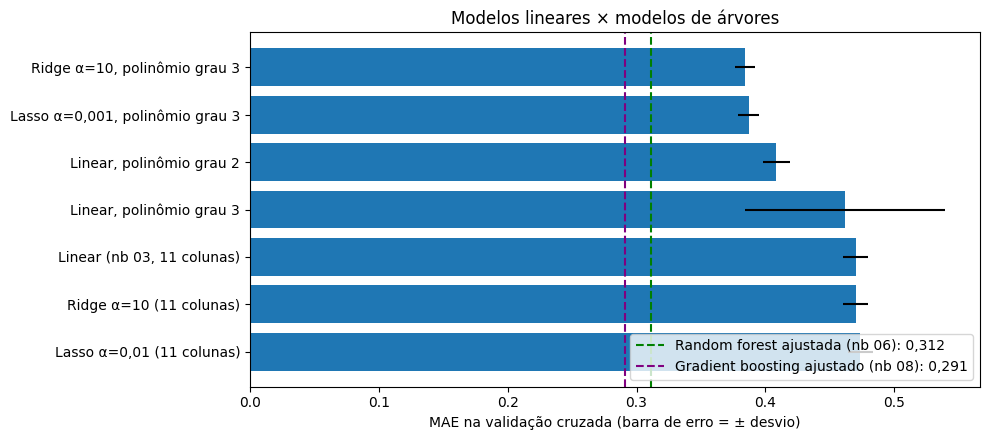

,MAE validação,± desvio,MAE treino,pior dobra
"Ridge α=10, polinômio grau 3",0.385,0.008,0.366,0.395
"Lasso α=0,001, polinômio grau 3",0.387,0.008,0.377,0.400
"Linear, polinômio grau 2",0.408,0.011,0.403,0.424
"Linear, polinômio grau 3",0.462,0.077,0.358,0.563
"Linear (nb 03, 11 colunas)",0.470,0.010,0.469,0.482
Ridge α=10 (11 colunas),0.470,0.009,0.469,0.482
"Lasso α=0,01 (11 colunas)",0.474,0.010,0.473,0.484


In [13]:
tabela = pd.DataFrame(placar).T.sort_values("MAE validação")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(tabela.index, tabela["MAE validação"], xerr=tabela["± desvio"])
ax.invert_yaxis()
# Referências dos notebooks anteriores (mesmas dobras):
ax.axvline(0.3116, color="green", linestyle="--", label="Random forest ajustada (nb 06): 0,312")
ax.axvline(0.2909, color="purple", linestyle="--", label="Gradient boosting ajustado (nb 08): 0,291")
ax.set_xlabel("MAE na validação cruzada (barra de erro = ± desvio)")
ax.set_title("Modelos lineares × modelos de árvores")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

tabela.round(4)

**Conclusão:**
- Com regularização e recursos polinomiais, a regressão linear foi de **0,470 para 0,385** (−18%). É o melhor modelo linear de toda a trilha.
- Repare na coluna **pior dobra**: o grau 3 sem regularização tem a pior dobra de todas (0,563), e o Ridge a reduz para 0,395. A regularização trouxe **estabilidade**, não só um erro médio menor.
- Mesmo assim, os modelos de árvores continuam bem à frente: random forest com **0,312** e gradient boosting com **0,291**. Para estes dados, com relações geográficas complexas, as árvores encontram os padrões de forma mais natural.

**Então por que usar modelos lineares?** Eles são **rápidos**, **leves**, mais **fáceis de explicar** (pelo menos sem polinômios) e funcionam bem com **poucos dados** ou com **muitas colunas**, como textos e dados genéticos. Nesses cenários, a regularização é indispensável.

## 11. Avaliação no teste

Como no notebook 08, temos um novo candidato escolhido **só pela validação cruzada**: o melhor modelo **linear** da trilha. Vamos avaliá-lo no teste **uma vez**, ao lado da regressão linear do notebook 03.

In [14]:
melhor_linear = pipeline_polinomial(3, Ridge(alpha=melhor_alfa))
melhor_linear.fit(X_train_full, y_train_full)
previsoes = melhor_linear.predict(X_test)

resultado = {
    "MAE": mean_absolute_error(y_test, previsoes),
    "RMSE": np.sqrt(mean_squared_error(y_test, previsoes)),
    "R²": r2_score(y_test, previsoes),
}
teste = pd.DataFrame({
    "Linear + pré-processamento (nb 03)": {"MAE": 0.464, "RMSE": 0.644, "R²": 0.684},
    f"Ridge α={melhor_alfa:.3g}, polinômio grau 3": resultado,
    "Gradient boosting ajustado (nb 08)": {"MAE": 0.279, "RMSE": 0.436, "R²": 0.855},
}).T
teste.round(3)

,MAE,RMSE,R²
Linear + pré-processamento (nb 03),0.464,0.644,0.684
"Ridge α=10, polinômio grau 3",0.387,0.582,0.741
Gradient boosting ajustado (nb 08),0.279,0.436,0.855


**Conclusão:** no teste, o modelo linear regularizado chegou a **MAE de 0,387** (≈ US\$ 38.700) e **R² de 0,741**, bem perto da estimativa da validação cruzada (0,385). Em relação à regressão linear do notebook 03 (0,464), são **17% menos erro**.

O gradient boosting (0,279) continua sendo o melhor modelo do projeto. Mas o caminho até aqui mostra que, com boa engenharia de atributos (notebook 03), recursos polinomiais e regularização, um modelo linear vai muito além de uma "reta".

## 12. Resumo

**Conceitos que você aprendeu**
- **Multicolinearidade** torna os coeficientes **instáveis**: as previsões continuam boas, mas a interpretação deixa de ser confiável.
- **Regularização:** custo = erro + α × tamanho dos coeficientes.
- **Ridge (L2):** encolhe todos os coeficientes e **estabiliza** colunas correlacionadas.
- **Lasso (L1):** zera coeficientes e faz **seleção de colunas**.
- **Padronizar antes de regularizar** é obrigatório.
- **Troca entre viés e variância:** aceitar coeficientes um pouco "errados" em troca de estabilidade.
- **Recursos polinomiais:** curvas e interações num modelo linear, ao custo de muitas colunas.
- **Regularização não cura underfitting.** Ela brilha quando há **muitas colunas** e risco de overfitting.

**Python novo:** `np.random.default_rng`, `gerador.choice`, `np.logspace`, `set_output(transform="pandas")`, `_` como variável descartada e legenda fora do gráfico (`bbox_to_anchor`).

**Para ir além:**
- **ElasticNet** combina as penalidades L1 e L2: seleciona colunas como o Lasso, mas lida melhor com grupos de colunas correlacionadas.
- **`RidgeCV` e `LassoCV`** escolhem o α automaticamente com validação cruzada, numa única linha.
- Em **redes neurais**, a mesma ideia aparece como *weight decay* (L2) e *dropout*.

Com isso, a trilha deste repositório fecha um ciclo: dos fundamentos (01 a 07) a dois aprofundamentos (08 e 09) que mostram as duas grandes famílias de modelos para dados em tabela, as **árvores combinadas** e os **modelos lineares regularizados**.